# Transformer: generating nondominated trajectories

A **causal Transformer in the style of the Decision Transformer** ([Chen et al., 2021](https://arxiv.org/abs/2106.01345)) writes the trajectory one move at a time. Instead of a fixed target, it is told at every step the **score still to earn**: the target minus what the agent has collected so far. This works because the scores add up step by step.

As with the LSTM, decoding can block moves that leave the grid or can no longer reach the goal in time (**constrained decoding**); the unconstrained run shows what the model learned on its own.

**Protocol (identical in all six generative-model notebooks).**

* **Grid:** the 4×4 example, start (4, 1), goal (1, 4), grass (2, 2), pool (3, 3), T = 10 steps. Scores: $\sum_t t \cdot 2^{-d_t} / \sum_t t$ for the grass and for the pool, both "higher is better".
* **Ground truth:** all 23,508 trajectories are listed, so the exact front is known: 29 score pairs, shared by 240 trajectories.
* **The front is held out.** Models train on the 23,268 dominated trajectories only (20,942 for training, 2,326 for validation), each labelled with its own scores. A model can only land on the front by producing something it never saw.
* **Test:** each model is asked for 20 target score pairs built from training data alone (slightly beyond the best training scores, in 20 directions from "all grass" to "all pool"), 50 samples per target: 1,000 trajectories per seed, 3 seeds.
* **Scoring** against the exact front, next to two baselines: random valid trajectories, and copying the training trajectories closest to each target.

Everything this notebook needs is in its own cells: no other file or notebook is required. Run all; on a CPU it takes about 7 minutes.

In [1]:
#@title Setup: grid, scoring, exact front, training data, evaluation
import json, math, os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# settings
CONFIG = {
    'rows': 4, 'cols': 4, 'start': (4, 1), 'goal': (1, 4),
    'landmarks': {'grass': (2, 2), 'pool': (3, 3)},   # two objectives, both "closer is better"
    'T': 10,                       # steps per trajectory (keep T <= 12: every trajectory is listed)
    'time_weight': 'linear',       # 'linear': w(t) = t (as written) | 'uniform': w = 1 | 'discount': w = gamma^t
    'gamma': 0.9,
    'hold_out_front': True,        # models never see a nondominated trajectory
    'validation_share': 0.1,
    'n_targets': 20,               # target score pairs asked for at test time
    'samples_per_target': 50,
    'target_push': 0.05,           # how far past the best training scores a target reaches (share of range)
    'seeds': [0, 1, 2],
    'results_dir': 'results',
}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

MOVE_NAMES = ['.', 'U', 'D', 'L', 'R']                        # token ids 0..4, '.' = wait one step
MOVE_DELTAS = np.array([(0, 0), (-1, 0), (1, 0), (0, -1), (0, 1)])
N_MOVES = len(MOVE_NAMES)
START_TOKEN = N_MOVES                                          # used by the autoregressive models
T, ROWS, COLS = CONFIG['T'], CONFIG['rows'], CONFIG['cols']
START, GOAL = np.array(CONFIG['start']), np.array(CONFIG['goal'])
OBJECTIVES = list(CONFIG['landmarks'])


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# scoring
def time_weights():
    t = np.arange(T + 1, dtype=float)
    return {'linear': t, 'uniform': np.ones_like(t), 'discount': CONFIG['gamma'] ** t}[CONFIG['time_weight']]


_W = time_weights()
_rows, _cols = np.meshgrid(np.arange(1, ROWS + 1), np.arange(1, COLS + 1), indexing='ij')
CLOSENESS = np.stack([2.0 ** -(np.abs(_rows - r) + np.abs(_cols - c))
                      for (r, c) in CONFIG['landmarks'].values()], axis=-1)       # 2^-d per cell
STEP_SCORE = _W[:, None, None, None] * CLOSENESS[None] / _W.sum()                 # (T+1, rows, cols, objectives)


def positions_from_moves(moves):
    """Move tokens (N, T) -> positions (N, T+1, 2) and a validity flag: every token is a move,
    the agent stays inside the grid at every step, and it is at the goal at step T."""
    moves = np.atleast_2d(np.asarray(moves))
    tokens_ok = np.all((moves >= 0) & (moves < N_MOVES), axis=1)
    deltas = MOVE_DELTAS[np.clip(moves, 0, N_MOVES - 1)]
    pos = np.concatenate([np.repeat(START[None, None], len(moves), axis=0),
                          START + np.cumsum(deltas, axis=1)], axis=1)
    inside = np.all((pos[..., 0] >= 1) & (pos[..., 0] <= ROWS) &
                    (pos[..., 1] >= 1) & (pos[..., 1] <= COLS), axis=1)
    at_goal = np.all(pos[:, -1] == GOAL, axis=1)
    return pos, tokens_ok & inside & at_goal


def score_positions(pos):
    """Positions inside the grid (N, T+1, 2) -> objective values (N, 2), larger is better."""
    t = np.arange(T + 1)[None]
    return STEP_SCORE[t, pos[..., 0] - 1, pos[..., 1] - 1].sum(axis=1)


def moves_to_text(moves):
    return ''.join(MOVE_NAMES[m] for m in moves)


# every trajectory and the exact front
def enumerate_trajectories():
    found, path = [], []

    def extend(r, c, t):
        if t == T:
            if r == GOAL[0] and c == GOAL[1]:
                found.append(list(path))
            return
        for k, (dr, dc) in enumerate(MOVE_DELTAS):
            nr, nc = r + dr, c + dc
            if 1 <= nr <= ROWS and 1 <= nc <= COLS and abs(nr - GOAL[0]) + abs(nc - GOAL[1]) <= T - t - 1:
                path.append(k)
                extend(nr, nc, t + 1)
                path.pop()

    extend(int(START[0]), int(START[1]), 0)
    return np.array(found, dtype=np.int64)


def nondominated_mask(V):
    """True for rows of V (two columns, both maximised) that no other row dominates; exact ties are kept."""
    R = np.round(np.asarray(V, float), 9)
    keep = np.zeros(len(R), bool)
    best_y, last = -np.inf, None
    for i in np.lexsort((-R[:, 1], -R[:, 0])):          # grass descending, then pool descending
        x, y = R[i]
        if y > best_y:
            best_y, last = y, (x, y)
            keep[i] = True
        elif (x, y) == last:
            keep[i] = True
    return keep


ALL_MOVES = enumerate_trajectories()
ALL_POS, _ = positions_from_moves(ALL_MOVES)
ALL_VALUES = score_positions(ALL_POS)
INDEX = {tuple(m): i for i, m in enumerate(ALL_MOVES.tolist())}
ON_FRONT = nondominated_mask(ALL_VALUES)
FRONT_VALUES = np.unique(np.round(ALL_VALUES[ON_FRONT], 9), axis=0)


def hypervolume_2d(P, ref):
    P = np.asarray(P, float)
    P = P[np.all(P > ref, axis=1)]
    if len(P) == 0:
        return 0.0
    P = P[nondominated_mask(P)]
    P = P[np.argsort(-P[:, 0])]
    area, prev_y = 0.0, ref[1]
    for x, y in P:
        if y > prev_y:
            area += (x - ref[0]) * (y - prev_y)
            prev_y = y
    return float(area)


HV_REF = FRONT_VALUES.min(0) - 0.1 * (FRONT_VALUES.max(0) - FRONT_VALUES.min(0))
HV_FRONT = hypervolume_2d(FRONT_VALUES, HV_REF)

# training data (front held out)
_split_rng = np.random.default_rng(12345)
_pool = np.where(~ON_FRONT)[0] if CONFIG['hold_out_front'] else np.arange(len(ALL_MOVES))
_pool = _split_rng.permutation(_pool)
_n_val = int(len(_pool) * CONFIG['validation_share'])
VAL_IDX, TRAIN_IDX = _pool[:_n_val], _pool[_n_val:]
SEEN = set(_pool.tolist())                      # everything a model could have seen
SCORE_MEAN = ALL_VALUES[TRAIN_IDX].mean(0)
SCORE_STD = ALL_VALUES[TRAIN_IDX].std(0)


def normalize_scores(v):
    return (np.asarray(v, float) - SCORE_MEAN) / SCORE_STD


def conditioning(targets, drop=None):
    """Targets (N, 2) in raw scores -> model input (N, 3): normalised scores plus a 'present' flag.
    With `drop`, a share of rows becomes the empty condition (all zeros), for classifier-free guidance."""
    c = torch.as_tensor(normalize_scores(targets), dtype=torch.float32)
    c = torch.cat([c, torch.ones(len(c), 1)], dim=1)
    if drop:
        c = c * (torch.rand(len(c), 1) >= drop).float()
    return c


def empty_conditioning(n):
    return torch.zeros(n, 3)


# targets asked for at test time
def reference_targets(values, k, push):
    """k target score pairs built from training data only. For k directions spread evenly between
    'all grass' and 'all pool', take the training trajectory that reaches farthest along that
    direction from the training data's worst corner, then push `push` (share of the range) further."""
    lo, hi = values.min(0), values.max(0)
    span = hi - lo
    u = (values - lo) / span
    targets = []
    for angle in np.linspace(0, np.pi / 2, k):
        d = np.array([np.cos(angle), np.sin(angle)])
        reach = np.min(np.where(d > 1e-9, u / np.maximum(d, 1e-9), np.inf), axis=1)
        best = np.flatnonzero(np.isclose(reach, reach.max()))
        i = best[np.argmax(u[best].sum(1))]
        targets.append(lo + (u[i] + push * d) * span)
    return np.array(targets)


TARGETS = reference_targets(ALL_VALUES[TRAIN_IDX], CONFIG['n_targets'], CONFIG['target_push'])
SPT = CONFIG['samples_per_target']
TARGETS_REPEATED = np.repeat(TARGETS, SPT, axis=0)

# evaluation and baselines
METRICS = {
    'valid': 'valid',
    'distinct': 'distinct',
    'on_front': 'on the front',
    'coverage': 'front points reached',
    'hv_ratio': 'hypervolume ratio',
    'target_error': 'target error',
}


def evaluate(moves, targets=None):
    """Score generated move sequences against the exact (held-out) front."""
    moves = np.atleast_2d(np.asarray(moves))
    pos, valid = positions_from_moves(moves)
    result = {'samples': len(moves), 'valid': float(valid.mean())}
    if not valid.any():
        result.update(distinct=0.0, on_front=0.0, coverage=0.0, hv_ratio=0.0, target_error=float('nan'))
        return result
    idx = np.array([INDEX[tuple(m)] for m in moves[valid].tolist()])
    values = ALL_VALUES[idx]
    hits = ON_FRONT[idx]
    reached = {tuple(v) for v in np.round(values[hits], 9)}
    result['distinct'] = len(set(idx.tolist())) / len(idx)
    result['on_front'] = float(hits.mean())
    result['coverage'] = len(reached) / len(FRONT_VALUES)
    result['hv_ratio'] = hypervolume_2d(values, HV_REF) / HV_FRONT
    result['target_error'] = (float(np.abs(values - np.asarray(targets)[valid]).mean())
                              if targets is not None else float('nan'))
    return result


def summarize(runs):
    """{method: [result per seed]} -> table of mean ± sd across seeds."""
    table = {}
    for method, results in runs.items():
        df = pd.DataFrame(results)
        row = {}
        for key, label in METRICS.items():
            m, s = df[key].mean(), df[key].std(ddof=0)
            row[label] = '–' if np.isnan(m) else (f'{m:.3f} ± {s:.3f}' if len(df) > 1 else f'{m:.3f}')
        table[method] = row
    return pd.DataFrame(table).T


def baseline_random(n, seed):
    """Valid trajectories drawn uniformly at random (no learning, no preferences)."""
    rng = np.random.default_rng(seed)
    return ALL_MOVES[rng.integers(0, len(ALL_MOVES), n)]


def baseline_copy_closest(targets, per_target):
    """For each target, copy the training trajectories whose scores are closest to it."""
    V = ALL_VALUES[TRAIN_IDX]
    picks = [TRAIN_IDX[np.argsort(np.abs(V - tg).sum(1), kind='stable')[:per_target]] for tg in targets]
    return ALL_MOVES[np.concatenate(picks)]


def legal_move_mask(r, c, t):
    """Rows and columns (N,) at step t -> (N, 5) moves that stay inside the grid and can still reach
    the goal by step T. Used for constrained decoding."""
    nr = r[:, None] + MOVE_DELTAS[None, :, 0]
    nc = c[:, None] + MOVE_DELTAS[None, :, 1]
    inside = (nr >= 1) & (nr <= ROWS) & (nc >= 1) & (nc <= COLS)
    return inside & (np.abs(nr - GOAL[0]) + np.abs(nc - GOAL[1]) <= T - t - 1)


# training loop
def fit(model, batch_loss, train_tensors, val_tensors, epochs, lr=2e-3, batch_size=256, seed=0):
    """Adam with gradient clipping; keeps the weights with the lowest validation loss.
    batch_loss(model, *batch) -> loss."""
    set_seed(seed)
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'validation': []}
    best, best_state = float('inf'), None
    n = len(train_tensors[0])
    for epoch in range(epochs):
        model.train()
        order, total = torch.randperm(n), 0.0
        for s in range(0, n, batch_size):
            b = order[s:s + batch_size]
            loss = batch_loss(model, *[x[b].to(DEVICE) for x in train_tensors])
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(b)
        history['train'].append(total / n)
        model.eval()
        rng_state = torch.get_rng_state()
        torch.manual_seed(999)                         # same noise for every validation pass
        with torch.no_grad():
            m, val = len(val_tensors[0]), 0.0
            for s in range(0, m, 1024):
                part = [x[s:s + 1024].to(DEVICE) for x in val_tensors]
                val += batch_loss(model, *part).item() * len(part[0])
        torch.set_rng_state(rng_state)
        history['validation'].append(val / m)
        if history['validation'][-1] < best:
            best = history['validation'][-1]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    model.eval()
    return history


# figures
GREY, BLUE, ORANGE, INK, INK2, GRIDLINE, SURFACE = ('#c3c2b7', '#2a78d6', '#eb6834', '#0b0b0b',
                                                    '#52514e', '#e1e0d9', '#fcfcfb')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 10,
                     'axes.edgecolor': GREY, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.facecolor': SURFACE, 'figure.facecolor': SURFACE})
pd.set_option('display.precision', 3)


def plot_scores(moves=None, targets=None, title='', ax=None):
    """Objective space: every trajectory (grey), generated trajectories (orange), the exact front
    (blue rings: an orange dot inside a ring is a front point that was hit) and the targets (black x)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5.4, 4.4))
    U = np.unique(np.round(ALL_VALUES, 9), axis=0)
    ax.scatter(U[:, 0], U[:, 1], s=7, color=GREY, linewidths=0, label='all trajectories', zorder=1)
    ax.plot(FRONT_VALUES[:, 0], FRONT_VALUES[:, 1], color=BLUE, lw=1, alpha=0.4, zorder=2)
    if moves is not None:
        pos, valid = positions_from_moves(moves)
        if valid.any():
            V = np.unique(np.round(score_positions(pos[valid]), 9), axis=0)
            ax.scatter(V[:, 0], V[:, 1], s=18, color=ORANGE, edgecolor=SURFACE, lw=0.6,
                       label='generated (valid)', zorder=3)
    ax.scatter(FRONT_VALUES[:, 0], FRONT_VALUES[:, 1], s=58, facecolor='none', edgecolor=BLUE, lw=1.6,
               label='exact front (held out)', zorder=4)
    if targets is not None:
        ax.scatter(targets[:, 0], targets[:, 1], s=28, marker='x', color=INK, lw=1.2,
                   label='targets asked for', zorder=5)
    ax.set_xlabel('grass (higher is better)')
    ax.set_ylabel('pool (higher is better)')
    ax.grid(color=GRIDLINE, lw=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8, loc='upper right')
    ax.set_title(title, loc='left')
    return ax


def plot_losses(histories, title='Training and validation loss'):
    fig, ax = plt.subplots(figsize=(5.4, 3.2))
    for k, h in enumerate(histories):
        ax.plot(h['train'], color=BLUE, lw=1.5, alpha=0.9, label='training' if k == 0 else None)
        ax.plot(h['validation'], color=ORANGE, lw=1.5, alpha=0.9, label='validation' if k == 0 else None)
    ax.set_xlabel('epoch')
    ax.set_ylabel('loss')
    ax.grid(color=GRIDLINE, lw=0.6)
    ax.legend(frameon=False, fontsize=8)
    ax.set_title(f'{title} (one line per seed)', loc='left')
    plt.show()


def _draw_grid(ax):
    from matplotlib.patches import Rectangle
    fills = {'grass': '#d6ecd2', 'pool': '#cde2fb'}
    for r in range(1, ROWS + 1):
        for c in range(1, COLS + 1):
            name = next((k for k, v in CONFIG['landmarks'].items() if tuple(v) == (r, c)), None)
            ax.add_patch(Rectangle((c - 1, ROWS - r), 1, 1, facecolor=fills.get(name, SURFACE),
                                   edgecolor=GRIDLINE, lw=1))
            if name:
                ax.text(c - 0.5, ROWS - r + 0.18, name, ha='center', va='center', fontsize=7, color=INK2)
    for cell, label in ((START, 'S'), (GOAL, 'G')):
        ax.text(cell[1] - 0.5, ROWS - cell[0] + 0.8, label, ha='center', va='center', fontsize=10,
                weight='bold', color=INK)
    ax.set_xlim(0, COLS)
    ax.set_ylim(0, ROWS)
    ax.set_aspect('equal')
    ax.axis('off')


def draw_paths(moves, titles=None, ncols=4, panel=2.5):
    """Small multiples, one trajectory per panel. Each move runs on its own right-hand lane so a
    step back is visible; a circle marks waiting, with the number of steps."""
    from matplotlib.patches import Circle
    moves = np.atleast_2d(moves)
    n = len(moves)
    nrows = int(math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, min(ncols, n), figsize=(panel * min(ncols, n), panel * nrows + 0.35))
    axes = np.atleast_1d(axes).ravel()
    for k, ax in enumerate(axes):
        if k >= n:
            ax.axis('off')
            continue
        _draw_grid(ax)
        pos, _ = positions_from_moves(moves[k])
        cen = np.stack([pos[0, :, 1] - 0.5, ROWS - pos[0, :, 0] + 0.5], axis=1) - [0, 0.1]
        segs = [(a, b) for a, b in zip(cen[:-1], cen[1:]) if np.hypot(*(b - a)) > 0]
        if segs:
            nrm = [np.array([(b - a)[1], -(b - a)[0]]) / np.hypot(*(b - a)) * 0.06 for a, b in segs]
            pts = [segs[0][0] + nrm[0]]
            for (a, b), n1, n2 in zip(segs[:-1], nrm[:-1], nrm[1:]):
                if np.allclose(n1, n2):
                    pts.append(b + n1)
                elif np.allclose(n1, -n2):
                    pts += [b + n1, b + n2]
                else:
                    pts.append(b + n1 + n2)
            pts.append(segs[-1][1] + nrm[-1])
            pts = np.array(pts)
            ax.plot(pts[:, 0], pts[:, 1], color=BLUE, lw=2, solid_joinstyle='miter')
            ax.scatter(pts[:1, 0], pts[:1, 1], s=30, color=BLUE, edgecolor=SURFACE, lw=1.5, zorder=4)
            a, b = segs[-1]
            ax.annotate('', xy=b + nrm[-1], xytext=a + nrm[-1] + (b - a) * 0.45,
                        arrowprops=dict(arrowstyle='-|>', color=BLUE, lw=2, mutation_scale=11,
                                        shrinkA=0, shrinkB=0))
        waits = {}
        for t in range(1, len(cen)):
            if np.allclose(cen[t], cen[t - 1]):
                waits[tuple(cen[t])] = waits.get(tuple(cen[t]), 0) + 1
        for (x, y), w in waits.items():
            ax.add_patch(Circle((x, y), 0.15, facecolor=SURFACE, edgecolor=BLUE, lw=1.8, zorder=5))
            ax.text(x, y, str(w), ha='center', va='center', fontsize=7, color=INK, zorder=6)
        if titles:
            ax.set_title(titles[k], fontsize=8, loc='left')
    fig.tight_layout()
    plt.show()


def save_results(model_name, runs, extra=None):
    os.makedirs(CONFIG['results_dir'], exist_ok=True)
    path = os.path.join(CONFIG['results_dir'], f'{model_name}.json')
    mean = lambda xs: float(np.mean([x for x in xs if not np.isnan(x)])) if any(not np.isnan(x) for x in xs) else None
    summary = {m: {k: mean([r[k] for r in rs]) for k in METRICS} for m, rs in runs.items()}
    with open(path, 'w') as f:
        json.dump({'model': model_name, 'config': CONFIG, 'summary': summary, 'runs': runs,
                   'extra': extra or {}}, f, indent=1, default=float)
    print('saved', path)


# report
print(f'device: {DEVICE}')
print(f'{len(ALL_MOVES):,} trajectories of {T} steps; exact front: {len(FRONT_VALUES)} score pairs '
      f'shared by {ON_FRONT.sum()} trajectories')
print(f'training {len(TRAIN_IDX):,} · validation {len(VAL_IDX):,} · held out (the front) '
      f'{len(ALL_MOVES) - len(SEEN):,}')
print(f'{len(TARGETS)} targets × {SPT} samples = {len(TARGETS_REPEATED):,} generated trajectories per model and seed')

device: cuda
23,508 trajectories of 10 steps; exact front: 29 score pairs shared by 240 trajectories
training 20,942 · validation 2,326 · held out (the front) 240
20 targets × 50 samples = 1,000 generated trajectories per model and seed


## 1. Training data, held-out front and targets

Grey: every trajectory's scores. Blue rings: the exact front, which the model never sees. Black crosses: the 20 targets it will be asked for, built from training data only.

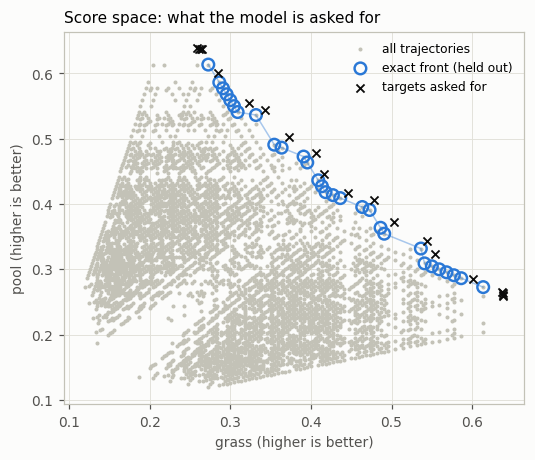

In [2]:
plot_scores(targets=TARGETS, title='Score space: what the model is asked for')
plt.show()

## 2. The model

Two Transformer layers, 64 dimensions, 4 attention heads, causal mask. The token for step $t$ adds up the previous move, the current cell and the score still to earn (divided by the training spread). Trained with cross-entropy on the next move.

In [3]:
CELL_COUNT = ROWS * COLS


def cell_ids(r, c):
    return (np.clip(r, 1, ROWS) - 1) * COLS + (np.clip(c, 1, COLS) - 1)


def returns_to_go(pos, targets):
    """Score still to earn after standing on position t, for t = 0..T-1 (N, T, 2)."""
    t = np.arange(T + 1)[None]
    earned = np.cumsum(STEP_SCORE[t, pos[..., 0] - 1, pos[..., 1] - 1], axis=1)[:, :T]
    return targets[:, None] - earned


class DecisionTransformer(nn.Module):
    """Causal Transformer in the style of the Decision Transformer. The token for step t adds up
    the previous move, the current cell and the score still to earn; the model predicts move t."""

    def __init__(self, d=64, layers=2, heads=4):
        super().__init__()
        self.move_embedding = nn.Embedding(N_MOVES + 1, d)
        self.cell_embedding = nn.Embedding(CELL_COUNT, d)
        self.to_go = nn.Linear(2, d)
        self.position = nn.Embedding(T, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, N_MOVES)
        self.register_buffer('causal', torch.triu(torch.full((T, T), float('-inf')), diagonal=1))

    def forward(self, previous, cells, to_go):
        L = previous.shape[1]
        x = (self.move_embedding(previous) + self.cell_embedding(cells) + self.to_go(to_go)
             + self.position.weight[:L])
        return self.head(self.norm(self.blocks(x, mask=self.causal[:L, :L])))


def transformer_loss(model, moves, cells, to_go):
    previous = torch.cat([torch.full_like(moves[:, :1], START_TOKEN), moves[:, :-1]], dim=1)
    logits = model(previous, cells, to_go)
    return F.cross_entropy(logits.reshape(-1, N_MOVES), moves.reshape(-1))


def training_tensors(idx):
    pos = ALL_POS[idx]
    to_go = returns_to_go(pos, ALL_VALUES[idx]) / SCORE_STD
    return (torch.as_tensor(ALL_MOVES[idx]), torch.as_tensor(cell_ids(pos[:, :T, 0], pos[:, :T, 1])),
            torch.as_tensor(to_go, dtype=torch.float32))


@torch.no_grad()
def generate_transformer(model, targets, seed, constrained=True):
    """One trajectory per row of `targets`; the score still to earn is updated after every move."""
    set_seed(seed)
    targets = np.asarray(targets, float)
    n = len(targets)
    r, c = np.full(n, START[0]), np.full(n, START[1])
    earned = STEP_SCORE[0, r - 1, c - 1].copy()
    previous, cells, to_go = [np.full(n, START_TOKEN)], [cell_ids(r, c)], [(targets - earned) / SCORE_STD]
    out = np.zeros((n, T), dtype=np.int64)
    for t in range(T):
        logits = model(torch.as_tensor(np.stack(previous, 1), device=DEVICE),
                       torch.as_tensor(np.stack(cells, 1), device=DEVICE),
                       torch.as_tensor(np.stack(to_go, 1), dtype=torch.float32, device=DEVICE))[:, -1]
        if constrained:
            allowed = torch.as_tensor(legal_move_mask(r, c, t), device=DEVICE)
            logits = logits.masked_fill(~allowed, -1e9)
        out[:, t] = torch.multinomial(F.softmax(logits, dim=-1), 1)[:, 0].cpu().numpy()
        r, c = r + MOVE_DELTAS[out[:, t], 0], c + MOVE_DELTAS[out[:, t], 1]
        if t + 1 < T:
            earned = earned + STEP_SCORE[t + 1, np.clip(r, 1, ROWS) - 1, np.clip(c, 1, COLS) - 1]
            previous.append(out[:, t])
            cells.append(cell_ids(r, c))
            to_go.append((targets - earned) / SCORE_STD)
    return out

## 3. Training (3 seeds, 25 epochs each)

Adam with gradient clipping; the weights with the lowest validation loss are kept.

seed 0: best validation loss 0.5645, 24 s
seed 1: best validation loss 0.5611, 16 s
seed 2: best validation loss 0.5614, 16 s


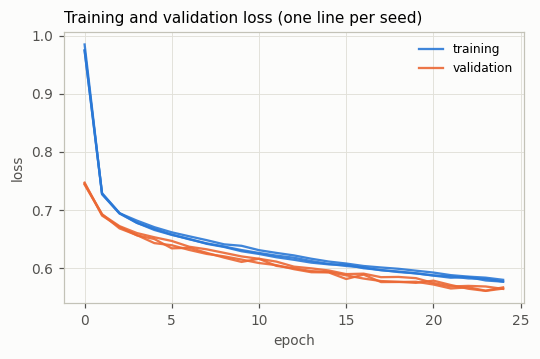

In [4]:
EPOCHS = 25
train_tensors, val_tensors = training_tensors(TRAIN_IDX), training_tensors(VAL_IDX)
models, histories = [], []
for seed in CONFIG['seeds']:
    start = time.time()
    model = DecisionTransformer()
    histories.append(fit(model, transformer_loss, train_tensors, val_tensors, epochs=EPOCHS, lr=0.002, seed=seed))
    models.append(model)
    print(f'seed {seed}: best validation loss {min(histories[-1]["validation"]):.4f}, {time.time() - start:.0f} s')

plot_losses(histories)

## 4. Results

What the columns mean (mean ± standard deviation over 3 seeds):

* **valid**: legal moves only, inside the grid, at G at step 10. All other columns count valid samples only.
* **distinct**: share of samples that are different trajectories (low = the model repeats itself).
* **on the front**: share of samples that are nondominated. Every trajectory off the front was in the training data, so this is also the share of samples the model never saw. Random sampling gets about 1%.
* **front points reached**: how many of the 29 front score pairs at least one sample hits.
* **hypervolume ratio**: area dominated by the samples divided by the front's, from a reference point just below the front's worst values. Close to 1 even for the baselines here, because the best dominated trajectories sit right next to the front; read it together with the two columns before it.
* **target error**: average gap between the scores asked for and the scores reached.

In [5]:
METHODS = ['Transformer, constrained decoding', 'Transformer, unconstrained']
runs = {name: [] for name in METHODS + ['Random valid trajectories', 'Copy closest training trajectories']}

samples = {}
for seed_index, (seed, model) in enumerate(zip(CONFIG['seeds'], models)):
    generators = {
        'Transformer, constrained decoding': lambda: generate_transformer(model, TARGETS_REPEATED, seed),
        'Transformer, unconstrained': lambda: generate_transformer(model, TARGETS_REPEATED, seed, constrained=False),
    }
    for name, generate in generators.items():
        moves = generate()
        runs[name].append(evaluate(moves, TARGETS_REPEATED))
        samples.setdefault(name, moves)          # keep seed 0 for the figures
    runs['Random valid trajectories'].append(evaluate(baseline_random(len(TARGETS_REPEATED), seed)))
    runs['Copy closest training trajectories'].append(
        evaluate(baseline_copy_closest(TARGETS, SPT), TARGETS_REPEATED))
summarize(runs)

,valid,distinct,on the front,front points reached,hypervolume ratio,target error
"Transformer, constrained decoding",1.000 ± 0.000,0.579 ± 0.035,0.175 ± 0.042,0.908 ± 0.016,0.996 ± 0.000,0.035 ± 0.002
"Transformer, unconstrained",0.557 ± 0.058,0.568 ± 0.051,0.249 ± 0.032,0.839 ± 0.033,0.995 ± 0.001,0.023 ± 0.002
Random valid trajectories,1.000 ± 0.000,0.979 ± 0.004,0.012 ± 0.001,0.299 ± 0.065,0.904 ± 0.009,–
Copy closest training trajectories,1.000 ± 0.000,0.425 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.929 ± 0.000,0.027 ± 0.000


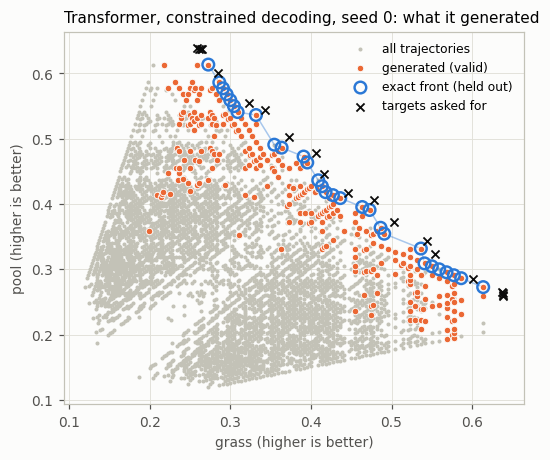

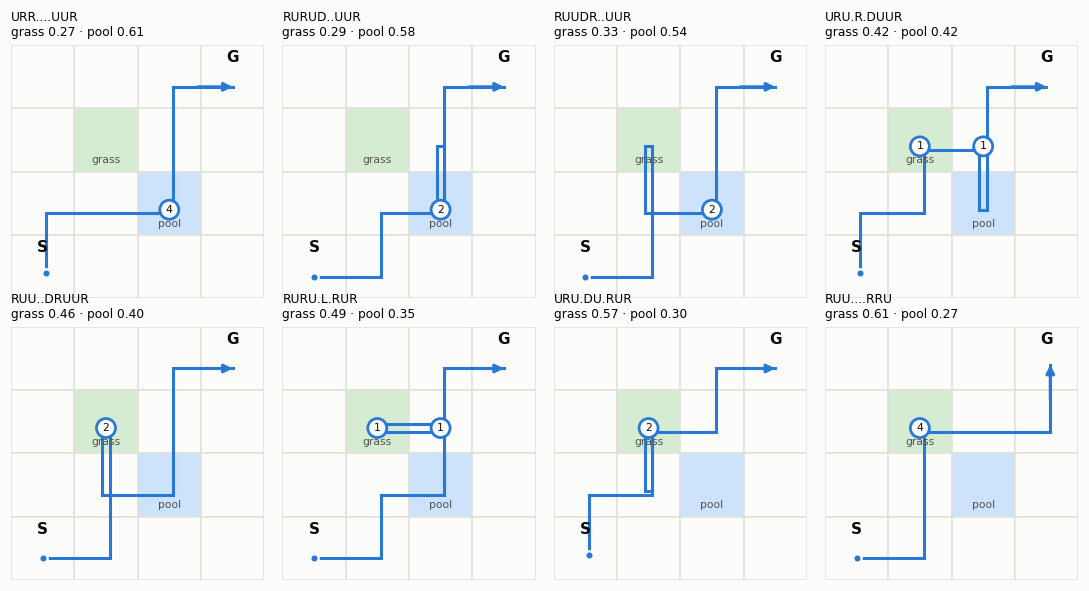

65 different front trajectories generated (seed 0), out of 240


In [6]:
moves = samples['Transformer, constrained decoding']
plot_scores(moves, targets=TARGETS, title='Transformer, constrained decoding, seed 0: what it generated')
plt.show()

# up to eight different front trajectories it found, which it never saw in training
pos, valid = positions_from_moves(moves)
idx = np.array([INDEX[tuple(m)] for m in moves[valid].tolist()])
found = list(dict.fromkeys(i for i in idx if ON_FRONT[i]))
found = sorted(found, key=lambda i: ALL_VALUES[i, 0])
pick = [found[k] for k in np.unique(np.linspace(0, len(found) - 1, min(8, len(found))).round().astype(int))] if found else []
if pick:
    draw_paths(ALL_MOVES[pick], [f'{moves_to_text(ALL_MOVES[i])}\ngrass {ALL_VALUES[i, 0]:.2f} · pool {ALL_VALUES[i, 1]:.2f}' for i in pick])
print(f'{len(found)} different front trajectories generated (seed 0), out of 240')

## 5. Diagnostic: asking for the exact front scores

Here the targets are the 29 held-out front score pairs themselves, 20 samples each. Real use would not know these scores, so this is not a result; it separates two reasons for missing the front: the model cannot produce those trajectories, or the shared targets point in the wrong place.

In [7]:
oracle_targets = np.repeat(FRONT_VALUES, 20, axis=0)
oracle = evaluate(generate_transformer(models[0], oracle_targets, 0), oracle_targets)
pd.DataFrame({'seed 0, asked for the exact front scores': {METRICS[k]: round(v, 3) for k, v in oracle.items() if k in METRICS}}).T

,valid,distinct,on the front,front points reached,hypervolume ratio,target error
"seed 0, asked for the exact front scores",1.0,0.874,0.133,0.966,0.999,0.025


## 6. Save the results

Writes `results/Transformer.json` (per-seed numbers and means) so the models can be compared later.

In [8]:
save_results('Transformer', runs, extra={'oracle_targets_seed0': oracle})

saved results/Transformer.json


## Reading

Numbers are means over the 3 seeds of this run

* **It finds front trajectories it never saw:** with constrained decoding, 20% of samples are on the front (random: 1.2%), reaching 27.3 of the 29 front points.
* **Score-to-go conditioning tracks the target well when left alone.** Unconstrained, its target error is 0.022, the lowest of any model, but only 61% of samples are valid (28% of the valid ones on the front, 17% of all samples).
* **Constraints and score-to-go pull against each other:** blocking moves raises validity to 100% but the front share drops from 28% to 20% of valid samples and the target error rises to 0.031.
* It repeats itself less than the LSTM (52% distinct vs 43%) but hits the front less often.
* Validation loss was still falling after 25 epochs, so a longer run may close part of the gap to the LSTM.